# No-alarm time-pocket mining

Plan: `time_pocket_mining_plan.md` (same folder). Scope is the no-alarm region only. The question is whether a contiguous circular hour window, optionally sliced on one categorical, changes a numeric's scale or mix enough to change what "unusual" means.

This is not a redo of M3/M4. Those tests asked whether the 24 hour labels (or 168 cells) associate with X globally. Here the clock wraps (hour 0 neighbors 23), the comparison is *inside* a category, and the readout is quantiles and age-band shares you can read, not CMI.

Modules: **P0** pictures, **P1** 72-window search, **P2** one clock-shuffle gate, **P3** ECDF gallery of keepers, **P4** fraud overlay on keepers, **P5** English takeaway (`drop` / `curiosity, still drop raw time` / `distill candidate`).


In [1]:
%load_ext autoreload
%autoreload 2

import importlib
import sys

from ccf_ml import file_utils
from ccf_ml.cross_validation import alarm as alarm_mod

importlib.reload(file_utils)
importlib.reload(alarm_mod)

from ccf_ml.cross_validation.alarm import alarm_flag_mask
from ccf_ml.cross_validation.constants import (
    ALARM_FLAG_COLUMNS,
    TARGET_COLUMN,
)
from ccf_ml.file_utils import (
    get_repo_root,
    get_script_plot_dir,
    get_script_table_dir,
    get_train_csv_path,
)
from ccf_ml.region_modeling.constants import REGION_ALWAYS_DROP
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import chi2_contingency, mannwhitneyu
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(get_repo_root() / "experiments" / "baselines"))
from features import CATEGORICAL_COLUMNS, NUMERIC_COLUMNS

DELIMITER_VALUE = "-" * 50
NOTEBOOK_STEM = "time_pocket_mining"
HOUR_COL = "time_of_day_hour"
DOW_COL = "day_of_week"
TIME_COLUMNS = (HOUR_COL, DOW_COL)
MERCHANT_COL = "merchant_category"
AMOUNT_COL = "amount_usd"
AGE_COL = "customer_age"
N_HOURS = 24
WINDOW_LENGTHS = (4, 6, 8)
MIN_SIDE = 2000
SHUFFLE_MARGIN = 1.1
SHUFFLE_SEED = 0
YOUNG_AGE_LOW = 18.0
YOUNG_AGE_HIGH = 25.0
AGE_BANDS = (
    ("[18,25]", 18.0, 25.0),
    ("[26,40]", 26.0, 40.0),
    ("[41,60]", 41.0, 60.0),
    ("[61+]", 61.0, None),
)
NAMED_WINDOWS = (
    ("night", 22, 6),
    ("morning", 6, 4),
    ("business", 9, 8),
    ("evening", 18, 4),
)
NAMED_WINDOW_SPANS = {
    "night": ((22.0, 24.0), (0.0, 4.0)),
    "morning": ((6.0, 10.0),),
    "business": ((9.0, 17.0),),
    "evening": ((18.0, 22.0),),
}
NAMED_WINDOW_COLORS = {
    "night": ("#4c78a8", 0.14),
    "morning": ("#f58518", 0.10),
    "business": ("#54a24b", 0.08),
    "evening": ("#b279a2", 0.10),
}
FEATURED_MERCHANT = "Crypto Exchange"
MEAN_AGE_RANGE_FLOOR = 2.0
P90_RATIO_FLOOR = 1.15
N_GALLERY = 20
MIN_FRAUD_ABOVE = 10
RATE_MARGIN = 1.1
ALL_SLICE_COL = "_all_"
ALL_SLICE_LEVEL = "no_alarm"
READOUT_P90 = "p90_ratio"
READOUT_YOUNG = "young_share"
SLICE_COLUMNS = tuple(
    column for column in CATEGORICAL_COLUMNS if column not in REGION_ALWAYS_DROP
)
NUMERIC_POCKET_COLUMNS = tuple(
    column for column in NUMERIC_COLUMNS if column not in TIME_COLUMNS
)
tables_dir = get_script_table_dir(NOTEBOOK_STEM)
train_df = pd.read_csv(get_train_csv_path())
has_alarm = alarm_flag_mask(train_df, columns=ALARM_FLAG_COLUMNS)
region = train_df.loc[~has_alarm.to_numpy()].copy()
n_region = len(region)
n_fraud = int(region[TARGET_COLUMN].sum())
MERCHANT_ORDER = region[MERCHANT_COL].value_counts().index.tolist()
print("no_alarm", n_region, n_fraud)
print("slice columns", SLICE_COLUMNS)
print("numeric columns", NUMERIC_POCKET_COLUMNS)
print("merchant_category levels", MERCHANT_ORDER)


c:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


no_alarm 646938 6931
slice columns ('merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_new_merchant')
numeric columns ('amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'merchant_risk_score', 'prior_disputes')
merchant_category levels ['Online Retail', 'Groceries', 'Restaurants', 'Fuel', 'Electronics', 'Streaming', 'Utilities', 'Healthcare', 'Travel', 'Gaming', 'Gift Cards', 'Crypto Exchange']


In [2]:
def window_label(*, start: int, length: int) -> str:
    """End-exclusive circular label, for example ``[22, 04)``."""
    end = (start + length) % N_HOURS
    return f"[{start:02d}, {end:02d})"


def build_windows() -> list[dict]:
    """Every circular interval of the pre-registered lengths."""
    n_windows = N_HOURS * len(WINDOW_LENGTHS)
    windows = [None] * n_windows
    index = 0
    for length in WINDOW_LENGTHS:
        for start in range(N_HOURS):
            hour_mask = np.zeros(N_HOURS, dtype=bool)
            for offset in range(length):
                hour_mask[(start + offset) % N_HOURS] = True
            windows[index] = {
                "start": int(start),
                "length": int(length),
                "label": window_label(start=start, length=length),
                "hour_mask": hour_mask,
                "in_hours": np.flatnonzero(hour_mask),
            }
            index += 1
    return windows


def build_slice_specs(frame: pd.DataFrame) -> list[tuple[str, str, np.ndarray]]:
    """No-slice baseline first, then one spec per level of each remaining cat."""
    n_rows = len(frame)
    specs = [(ALL_SLICE_COL, ALL_SLICE_LEVEL, np.ones(n_rows, dtype=bool))]
    for column in SLICE_COLUMNS:
        values = frame[column].to_numpy()
        levels = pd.unique(frame[column])
        n_levels = len(levels)
        for i in range(n_levels):
            level = levels[i]
            specs.append((column, str(level), values == level))
    return specs


def log_p90_extremity(*, p90_in: float, p90_out: float) -> float:
    """Absolute log ratio; undefined when either quantile is not positive."""
    if p90_in <= 0.0 or p90_out <= 0.0:
        return float("nan")
    return float(abs(np.log(p90_in / p90_out)))


def young_share(ages: np.ndarray) -> float:
    """Share of ages in the closed interval [18, 25]."""
    return float(np.mean((ages >= YOUNG_AGE_LOW) & (ages <= YOUNG_AGE_HIGH)))


def format_number(value: float, *, numeric_name: str) -> str:
    """USD-style for amount; otherwise a short decimal."""
    if numeric_name == AMOUNT_COL:
        return f"${value:,.2f}"
    if numeric_name == AGE_COL:
        return f"{value:.1f}y"
    return f"{value:.3g}"


def story_sentence(row: pd.Series) -> str:
    """One readable sentence for a pocket row."""
    if row["slice_col"] == ALL_SLICE_COL:
        slice_txt = "no-alarm overall"
    else:
        slice_txt = f"{row['slice_col']}={row['slice_level']}"
    window = row["window_label"]
    n_in = int(row["n_in"])
    n_out = int(row["n_out"])
    if row["readout"] == READOUT_YOUNG:
        share_in = 100.0 * float(row["young_share_in"])
        share_out = 100.0 * float(row["young_share_out"])
        return (
            f"Hours {window} + {slice_txt}: share of ages [18, 25] is "
            f"{share_in:.1f}% inside vs {share_out:.1f}% outside "
            f"(n_in={n_in:,}, n_out={n_out:,})"
        )
    numeric_name = str(row["numeric"])
    p90_in = format_number(float(row["p90_in"]), numeric_name=numeric_name)
    p90_out = format_number(float(row["p90_out"]), numeric_name=numeric_name)
    return (
        f"Hours {window} + {slice_txt}: {numeric_name} p90 is "
        f"{p90_in} inside vs {p90_out} outside "
        f"(n_in={n_in:,}, n_out={n_out:,})"
    )


def shade_named_windows(ax) -> None:
    """Draw the four named windows on a 0-24 hour axis."""
    for name, spans in NAMED_WINDOW_SPANS.items():
        color, alpha = NAMED_WINDOW_COLORS[name]
        for i, (left, right) in enumerate(spans):
            label = name if i == 0 else None
            ax.axvspan(left, right, color=color, alpha=alpha, zorder=0, label=label)


def heatmap_hour_lines(ax) -> None:
    """Named-window edges on an hour-indexed heatmap."""
    for edge in (4, 6, 9, 10, 17, 18, 22):
        ax.axvline(edge - 0.5, color="0.55", lw=0.6, ls=":")


def slice_mask_from_spec(
    slice_col: str,
    slice_level: str,
    *,
    slice_lookup: dict[tuple[str, str], np.ndarray],
) -> np.ndarray:
    """Boolean mask for a (column, level) pair recorded during the search."""
    key = (slice_col, slice_level)
    if key not in slice_lookup:
        raise KeyError(f"unknown slice {key!r}")
    return slice_lookup[key]


def search_pockets(
    *,
    hours: np.ndarray,
    numeric_values: dict[str, np.ndarray],
    slice_specs: list[tuple[str, str, np.ndarray]],
    windows: list[dict],
    keep_rows: bool,
    progress_desc: str,
) -> tuple[pd.DataFrame, dict[tuple, dict]]:
    """Compare each window to its complement inside every slice.

    Returns every occupancy-valid row when ``keep_rows`` is true, and the
    most extreme window per (slice, numeric, readout) either way.
    """
    n_specs = len(slice_specs)
    n_numerics = len(NUMERIC_POCKET_COLUMNS)
    n_windows = len(windows)
    n_max = n_specs * n_numerics * n_windows
    if keep_rows:
        rows = [None] * n_max
    else:
        rows = None
    n_filled = 0
    extremes: dict[tuple, dict] = {}
    n_jobs = n_specs * n_numerics
    progress = tqdm(total=n_jobs, desc=progress_desc)
    for slice_col, slice_level, slice_mask in slice_specs:
        n_slice = int(slice_mask.sum())
        if n_slice < (2 * MIN_SIDE):
            progress.update(n_numerics)
            continue
        slice_hours = hours[slice_mask]
        hour_index = [None] * N_HOURS
        hour_n = [0] * N_HOURS
        for hour in range(N_HOURS):
            hour_index[hour] = np.flatnonzero(slice_hours == hour)
            hour_n[hour] = int(hour_index[hour].size)
        for numeric_name in NUMERIC_POCKET_COLUMNS:
            slice_num = numeric_values[numeric_name][slice_mask]
            hour_vals = [None] * N_HOURS
            for hour in range(N_HOURS):
                hour_vals[hour] = slice_num[hour_index[hour]]
            is_age = numeric_name == AGE_COL
            for window in windows:
                in_hours = window["in_hours"]
                n_in = 0
                for hour in in_hours:
                    n_in += hour_n[hour]
                n_out = n_slice - n_in
                if n_in < MIN_SIDE or n_out < MIN_SIDE:
                    continue
                in_parts = [None] * int(window["length"])
                out_parts = [None] * (N_HOURS - int(window["length"]))
                in_i = 0
                out_i = 0
                for hour in range(N_HOURS):
                    if window["hour_mask"][hour]:
                        in_parts[in_i] = hour_vals[hour]
                        in_i += 1
                    else:
                        out_parts[out_i] = hour_vals[hour]
                        out_i += 1
                vals_in = np.concatenate(in_parts)
                vals_out = np.concatenate(out_parts)
                p50_in, p90_in, p95_in = np.quantile(
                    vals_in, (0.5, 0.9, 0.95)
                )
                p50_out, p90_out, p95_out = np.quantile(
                    vals_out, (0.5, 0.9, 0.95)
                )
                if p90_out > 0.0:
                    p90_ratio = float(p90_in / p90_out)
                else:
                    p90_ratio = float("nan")
                p90_ext = log_p90_extremity(p90_in=float(p90_in), p90_out=float(p90_out))
                if is_age:
                    young_in = young_share(vals_in)
                    young_out = young_share(vals_out)
                    young_diff = float(abs(young_in - young_out))
                else:
                    young_in = float("nan")
                    young_out = float("nan")
                    young_diff = float("nan")
                base = {
                    "slice_col": slice_col,
                    "slice_level": slice_level,
                    "numeric": numeric_name,
                    "window_label": window["label"],
                    "window_start": window["start"],
                    "window_length": window["length"],
                    "n_in": n_in,
                    "n_out": n_out,
                    "p50_in": float(p50_in),
                    "p50_out": float(p50_out),
                    "p90_in": float(p90_in),
                    "p90_out": float(p90_out),
                    "p95_in": float(p95_in),
                    "p95_out": float(p95_out),
                    "p90_ratio": p90_ratio,
                    "p90_extremity": p90_ext,
                    "young_share_in": young_in,
                    "young_share_out": young_out,
                    "young_share_diff": young_diff,
                }
                if keep_rows:
                    rows[n_filled] = base
                    n_filled += 1
                if np.isfinite(p90_ext):
                    key = (slice_col, slice_level, numeric_name, READOUT_P90)
                    current = extremes.get(key)
                    if current is None or p90_ext > current["extremity"]:
                        extremes[key] = {
                            **base,
                            "readout": READOUT_P90,
                            "extremity": p90_ext,
                        }
                if is_age and np.isfinite(young_diff):
                    key = (slice_col, slice_level, numeric_name, READOUT_YOUNG)
                    current = extremes.get(key)
                    if current is None or young_diff > current["extremity"]:
                        extremes[key] = {
                            **base,
                            "readout": READOUT_YOUNG,
                            "extremity": young_diff,
                        }
            progress.update(1)
    progress.close()
    if keep_rows:
        search_table = pd.DataFrame(rows[:n_filled])
    else:
        search_table = pd.DataFrame()
    return search_table, extremes


WINDOWS = build_windows()
print("windows", len(WINDOWS))
hours = region[HOUR_COL].to_numpy(dtype=np.int64)
if hours.min() < 0 or hours.max() > 23:
    raise ValueError("time_of_day_hour is not in 0..23")
y = region[TARGET_COLUMN].to_numpy(dtype=np.int64)
numeric_values = {}
for column in NUMERIC_POCKET_COLUMNS:
    numeric_values[column] = region[column].to_numpy(dtype=np.float64)
slice_specs = build_slice_specs(region)
slice_lookup = {}
for slice_col, slice_level, slice_mask in slice_specs:
    slice_lookup[(slice_col, slice_level)] = slice_mask
print("slices", len(slice_specs))
for slice_col, slice_level, slice_mask in slice_specs:
    print(f"  {slice_col}={slice_level}  n={int(slice_mask.sum()):,}")


windows 72
slices 38
  _all_=no_alarm  n=646,938
  merchant_category=Groceries  n=131,379
  merchant_category=Online Retail  n=143,765
  merchant_category=Electronics  n=44,804
  merchant_category=Healthcare  n=33,118
  merchant_category=Restaurants  n=93,777
  merchant_category=Utilities  n=39,041
  merchant_category=Fuel  n=55,597
  merchant_category=Streaming  n=43,605
  merchant_category=Crypto Exchange  n=4,836
  merchant_category=Gaming  n=21,827
  merchant_category=Travel  n=26,500
  merchant_category=Gift Cards  n=8,689
  card_type=Mastercard  n=235,466
  card_type=Visa  n=318,953
  card_type=Amex  n=42,304
  card_type=RuPay  n=34,322
  card_type=Discover  n=15,893
  auth_method=OTP  n=162,123
  auth_method=PIN  n=142,498
  auth_method=3D Secure  n=193,970
  auth_method=Biometric  n=86,904
  auth_method=No Authentication  n=61,443
  channel=POS  n=193,362
  channel=In-App  n=77,692
  channel=Online  n=248,495
  channel=Contactless  n=99,059
  channel=ATM  n=28,330
  device_type

## P0: pictures before any search

Hour × merchant heatmaps of amount p50, amount p90 (USD), and mean customer age. A companion heatmap divides each merchant's hourly p90 by that merchant's overall p90 so a night dip is visible across different ticket sizes. Line plots shade the four named windows (night wraps midnight). Mix bars always include Crypto Exchange, plus any merchant whose hourly mean-age range exceeds 2 years or whose max/min hourly p90 ratio exceeds 1.15.

If these plots are visually flat, P1 is unlikely to find a trustworthy pocket.


saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\tables\p0_hour_merchant_stats.csv
age range by merchant (years)
merchant_category
Online Retail      1.012
Groceries          0.900
Restaurants        1.062
Fuel               1.274
Electronics        1.568
Streaming          1.633
Utilities          1.631
Healthcare         2.484
Travel             2.845
Gaming             1.758
Gift Cards         3.720
Crypto Exchange    4.145
--------------------------------------------------
hourly p90 max/min by merchant
merchant_category
Online Retail      1.021
Groceries          1.025
Restaurants        1.049
Fuel               1.064
Electronics        1.086
Streaming          1.098
Utilities          1.067
Healthcare         1.084
Travel             1.190
Gaming             1.072
Gift Cards         1.088
Crypto Exchange    1.319
--------------------------------------------------
mix-bar merchants ['Healthcare', 'Travel', 'Gi

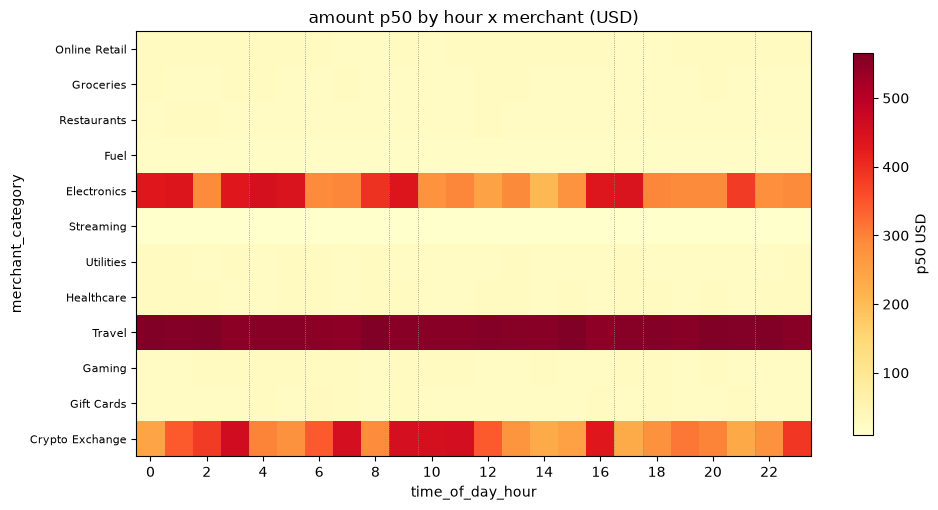

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p0_pictures\amount_p90_heatmap.png


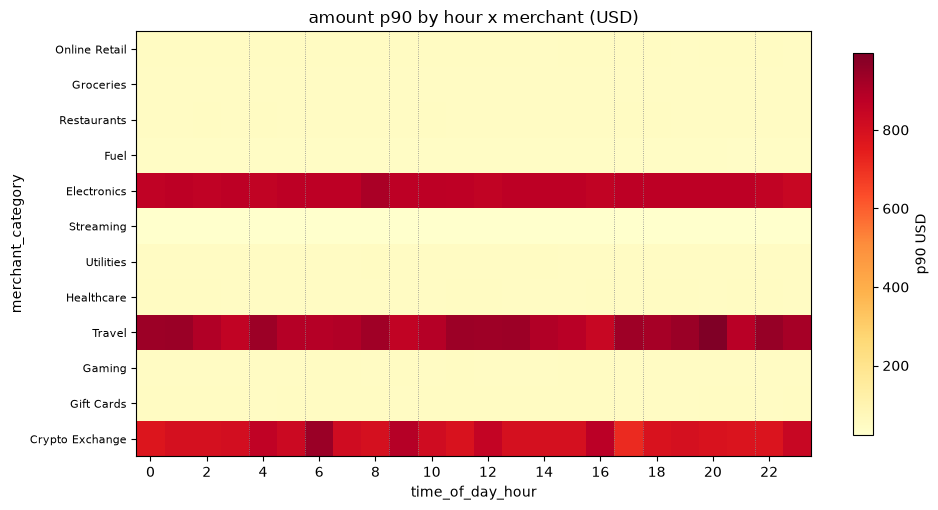

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p0_pictures\amount_p90_relative_heatmap.png


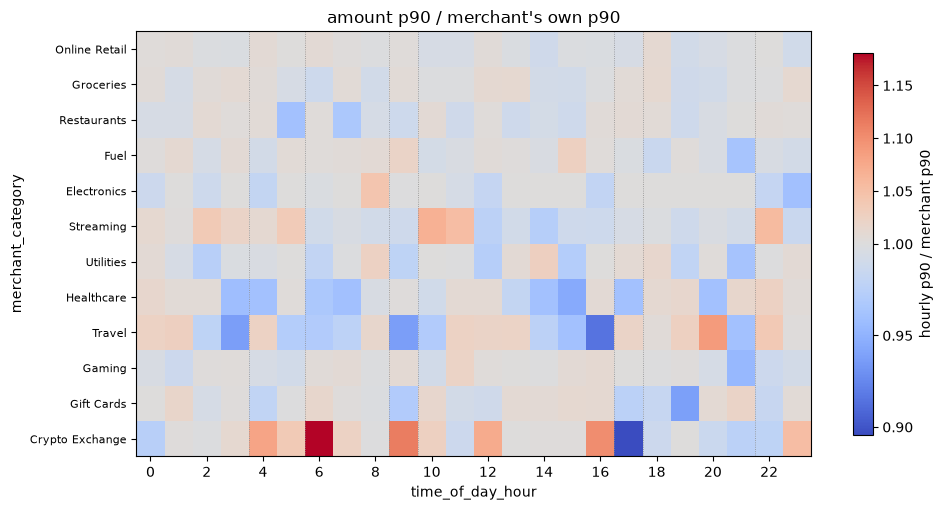

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p0_pictures\mean_age_heatmap.png


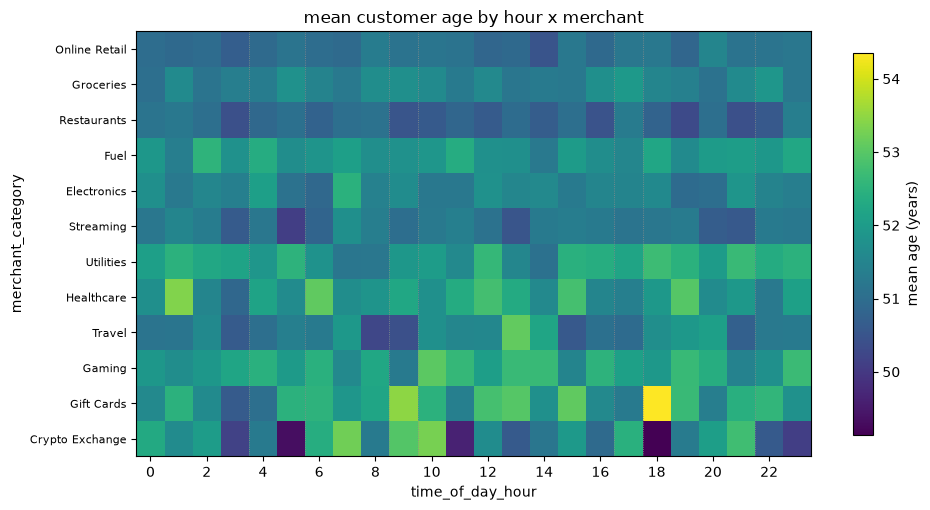

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p0_pictures\p90_and_age_lines.png


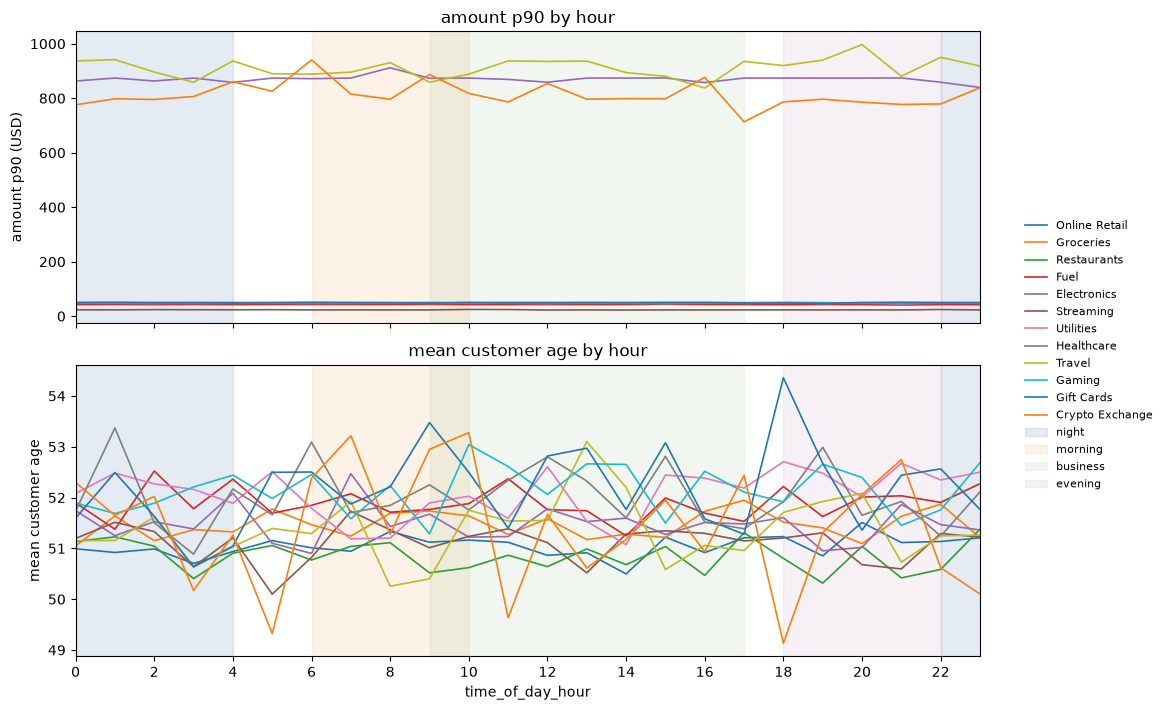

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p0_pictures\age_band_mix_bars.png


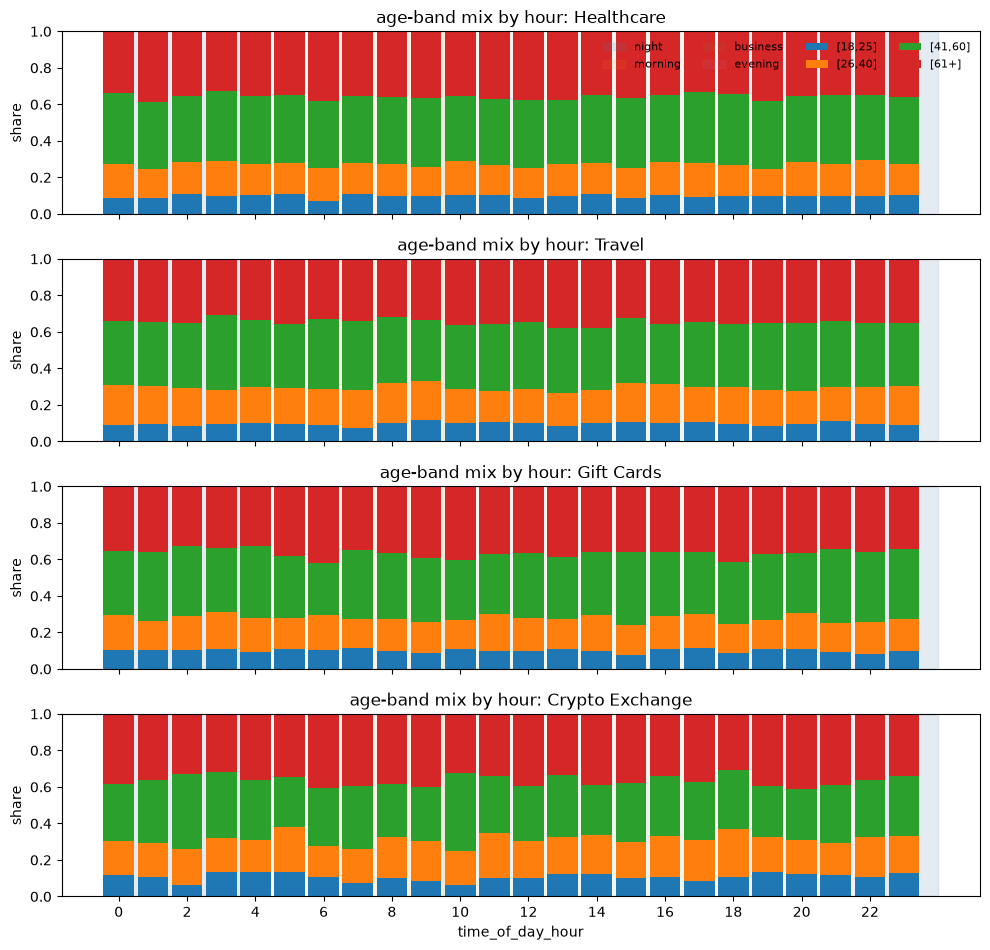

In [3]:
hour_merchant = region.groupby([HOUR_COL, MERCHANT_COL], observed=True)
p50_grid = (
    hour_merchant[AMOUNT_COL]
    .quantile(0.5)
    .unstack()
    .reindex(index=range(N_HOURS), columns=MERCHANT_ORDER)
)
p90_grid = (
    hour_merchant[AMOUNT_COL]
    .quantile(0.9)
    .unstack()
    .reindex(index=range(N_HOURS), columns=MERCHANT_ORDER)
)
mean_age_grid = (
    hour_merchant[AGE_COL]
    .mean()
    .unstack()
    .reindex(index=range(N_HOURS), columns=MERCHANT_ORDER)
)
n_grid = (
    hour_merchant[AMOUNT_COL]
    .size()
    .unstack()
    .reindex(index=range(N_HOURS), columns=MERCHANT_ORDER)
)
if p50_grid.isna().to_numpy().any() or p90_grid.isna().to_numpy().any():
    raise ValueError("hour x merchant quantile grid has empty cells")
if mean_age_grid.isna().to_numpy().any():
    raise ValueError("hour x merchant mean-age grid has empty cells")

merchant_p90 = region.groupby(MERCHANT_COL, observed=True)[AMOUNT_COL].quantile(0.9)
p90_relative = p90_grid.div(merchant_p90.reindex(MERCHANT_ORDER), axis=1)

p0_stats = pd.concat(
    {
        "n": n_grid.stack(),
        "amount_p50": p50_grid.stack(),
        "amount_p90": p90_grid.stack(),
        "amount_p90_relative": p90_relative.stack(),
        "mean_customer_age": mean_age_grid.stack(),
    },
    axis=1,
).reset_index()
p0_stats_path = tables_dir / "p0_hour_merchant_stats.csv"
p0_stats.to_csv(p0_stats_path, index=False)
print("saved", p0_stats_path)

age_range = mean_age_grid.max(axis=0) - mean_age_grid.min(axis=0)
p90_mm_ratio = p90_grid.max(axis=0) / p90_grid.min(axis=0)
selected_merchants = []
n_merchants = len(MERCHANT_ORDER)
for i in range(n_merchants):
    merchant = MERCHANT_ORDER[i]
    if merchant == FEATURED_MERCHANT:
        selected_merchants.append(merchant)
        continue
    if float(age_range[merchant]) > MEAN_AGE_RANGE_FLOOR:
        selected_merchants.append(merchant)
        continue
    if float(p90_mm_ratio[merchant]) > P90_RATIO_FLOOR:
        selected_merchants.append(merchant)
if FEATURED_MERCHANT not in selected_merchants:
    selected_merchants.insert(0, FEATURED_MERCHANT)
print("age range by merchant (years)")
print(age_range.round(3).to_string())
print(DELIMITER_VALUE)
print("hourly p90 max/min by merchant")
print(p90_mm_ratio.round(3).to_string())
print(DELIMITER_VALUE)
print("mix-bar merchants", selected_merchants)

p0_dir = get_script_plot_dir(NOTEBOOK_STEM, section="p0_pictures")


def plot_merchant_heatmap(grid: pd.DataFrame, *, title: str, cbar_label: str, cmap, norm, path):
    """Hour columns, merchant rows."""
    fig, ax = plt.subplots(figsize=(10.0, 5.2))
    im = ax.imshow(
        grid.to_numpy(dtype=np.float64).T,
        aspect="auto",
        cmap=cmap,
        norm=norm,
    )
    ax.set_xticks(np.arange(0, N_HOURS, 2))
    ax.set_xticklabels([str(hour) for hour in range(0, N_HOURS, 2)])
    ax.set_xlabel(HOUR_COL)
    ax.set_yticks(np.arange(len(grid.columns)))
    ax.set_yticklabels(list(grid.columns), fontsize=8)
    ax.set_ylabel(MERCHANT_COL)
    ax.set_title(title)
    heatmap_hour_lines(ax)
    fig.colorbar(im, ax=ax, shrink=0.9, label=cbar_label)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    print("saved", path)
    plt.show()
    plt.close(fig)


plot_merchant_heatmap(
    p50_grid,
    title="amount p50 by hour x merchant (USD)",
    cbar_label="p50 USD",
    cmap="YlOrRd",
    norm=None,
    path=p0_dir / "amount_p50_heatmap.png",
)
plot_merchant_heatmap(
    p90_grid,
    title="amount p90 by hour x merchant (USD)",
    cbar_label="p90 USD",
    cmap="YlOrRd",
    norm=None,
    path=p0_dir / "amount_p90_heatmap.png",
)
plot_merchant_heatmap(
    p90_relative,
    title="amount p90 / merchant's own p90",
    cbar_label="hourly p90 / merchant p90",
    cmap="coolwarm",
    norm=TwoSlopeNorm(vcenter=1.0),
    path=p0_dir / "amount_p90_relative_heatmap.png",
)
plot_merchant_heatmap(
    mean_age_grid,
    title="mean customer age by hour x merchant",
    cbar_label="mean age (years)",
    cmap="viridis",
    norm=None,
    path=p0_dir / "mean_age_heatmap.png",
)

fig, axes = plt.subplots(2, 1, figsize=(10.0, 7.2), sharex=True)
for merchant in MERCHANT_ORDER:
    axes[0].plot(p90_grid.index, p90_grid[merchant], lw=1.2, label=merchant)
    axes[1].plot(mean_age_grid.index, mean_age_grid[merchant], lw=1.2, label=merchant)
for ax in axes:
    shade_named_windows(ax)
    ax.set_xlim(0, 23)
    ax.set_xticks(range(0, N_HOURS, 2))
axes[0].set_ylabel("amount p90 (USD)")
axes[0].set_title("amount p90 by hour")
axes[1].set_ylabel("mean customer age")
axes[1].set_xlabel(HOUR_COL)
axes[1].set_title("mean customer age by hour")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=8,
    frameon=False,
)
fig.tight_layout()
line_path = p0_dir / "p90_and_age_lines.png"
fig.savefig(line_path, dpi=140, bbox_inches="tight")
print("saved", line_path)
plt.show()
plt.close(fig)

ages = region[AGE_COL].to_numpy(dtype=np.float64)
merchants_arr = region[MERCHANT_COL].to_numpy()
n_selected = len(selected_merchants)
fig, axes = plt.subplots(
    n_selected,
    1,
    figsize=(10.0, 2.4 * n_selected),
    sharex=True,
    squeeze=False,
)
band_names = [name for name, _lo, _hi in AGE_BANDS]
for m_i in range(n_selected):
    merchant = selected_merchants[m_i]
    ax = axes[m_i, 0]
    merchant_hours = hours[merchants_arr == merchant]
    merchant_ages = ages[merchants_arr == merchant]
    shares = np.zeros((len(AGE_BANDS), N_HOURS), dtype=np.float64)
    for hour in range(N_HOURS):
        hour_ages = merchant_ages[merchant_hours == hour]
        if hour_ages.size == 0:
            raise ValueError(f"empty hour {hour} for merchant {merchant!r}")
        for b_i, (_name, low, high) in enumerate(AGE_BANDS):
            if high is None:
                shares[b_i, hour] = float(np.mean(hour_ages >= low))
            else:
                shares[b_i, hour] = float(
                    np.mean((hour_ages >= low) & (hour_ages <= high))
                )
    bottom = np.zeros(N_HOURS, dtype=np.float64)
    for b_i in range(len(AGE_BANDS)):
        ax.bar(
            np.arange(N_HOURS),
            shares[b_i],
            bottom=bottom,
            width=0.9,
            label=band_names[b_i],
        )
        bottom = bottom + shares[b_i]
    shade_named_windows(ax)
    ax.set_ylim(0.0, 1.0)
    ax.set_ylabel("share")
    ax.set_title(f"age-band mix by hour: {merchant}")
    if m_i == 0:
        ax.legend(loc="upper right", fontsize=8, frameon=False, ncol=4)
axes[-1, 0].set_xlabel(HOUR_COL)
axes[-1, 0].set_xticks(range(0, N_HOURS, 2))
fig.tight_layout()
mix_path = p0_dir / "age_band_mix_bars.png"
fig.savefig(mix_path, dpi=140)
print("saved", mix_path)
plt.show()
plt.close(fig)


## P1: systematic window search

72 circular windows (lengths 4, 6, 8 × 24 starts). For each remaining categorical level, plus the no-slice baseline, compare inside the window vs the rest of that slice. Occupancy floor: `n_in >= 2000` and `n_out >= 2000`. Headline columns are counts, p50 / p90 / p95, the p90 ratio, and for age the [18, 25] share. No p-values here.


In [4]:
search_table, observed_extremes = search_pockets(
    hours=hours,
    numeric_values=numeric_values,
    slice_specs=slice_specs,
    windows=WINDOWS,
    keep_rows=True,
    progress_desc="P1 observed",
)
if search_table.empty:
    raise ValueError("window search produced no occupancy-valid rows")
search_path = tables_dir / "window_search.csv"
search_table.to_csv(search_path, index=False)
print("search rows", len(search_table))
print("saved", search_path)
print(DELIMITER_VALUE)
print("largest |log p90_in/p90_out| (amount_usd, top 10)")
amount_search = search_table.loc[search_table["numeric"] == AMOUNT_COL].copy()
amount_search = amount_search.sort_values("p90_extremity", ascending=False)
print(
    amount_search[
        [
            "slice_col",
            "slice_level",
            "window_label",
            "n_in",
            "n_out",
            "p90_in",
            "p90_out",
            "p90_ratio",
        ]
    ]
    .head(10)
    .to_string(index=False)
)
print(DELIMITER_VALUE)
print("largest |young share in - out| (customer_age, top 10)")
age_search = search_table.loc[search_table["numeric"] == AGE_COL].copy()
age_search = age_search.sort_values("young_share_diff", ascending=False)
print(
    age_search[
        [
            "slice_col",
            "slice_level",
            "window_label",
            "n_in",
            "n_out",
            "young_share_in",
            "young_share_out",
            "young_share_diff",
        ]
    ]
    .head(10)
    .to_string(index=False)
)


P1 observed: 100%|██████████| 418/418 [00:51<00:00,  8.15it/s]


search rows 29040
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\tables\window_search.csv
--------------------------------------------------
largest |log p90_in/p90_out| (amount_usd, top 10)
  slice_col slice_level window_label  n_in  n_out  p90_in  p90_out  p90_ratio
  card_type    Discover     [05, 09)  2505  13388 109.598   72.002   1.522152
device_type ATM Machine     [16, 20)  3263  16105 157.082  103.242   1.521493
device_type         Mac     [13, 17)  5567  25885  73.226  109.678   0.667645
  card_type    Discover     [04, 10)  3794  12099 104.942   71.792   1.461751
device_type         Mac     [12, 16)  5661  25791  76.150  110.080   0.691770
  card_type    Discover     [06, 10)  2611  13282 103.990   71.989   1.444526
device_type Smart Watch     [21, 01)  3178  16322  87.383   60.619   1.441512
device_type ATM Machine     [13, 17)  3423  15945  77.794  111.654   0.696742
  card_type    Discover     [03, 

## P2: one statistical gate (shuffled clock)

Overlapping windows always produce a "best" window. For each (slice, numeric, readout) we keep the most extreme real window only if its extremity beats `1.1 ×` the most extreme window found after scrambling `time_of_day_hour` once. Numerics and categoricals stay put. That is the same idea as repaired M4b, said in English: if the clock were fake, would we still find a window this extreme?


In [5]:
rng = np.random.default_rng(SHUFFLE_SEED)
shuffled_hours = rng.permutation(hours)
_null_table, null_extremes = search_pockets(
    hours=shuffled_hours,
    numeric_values=numeric_values,
    slice_specs=slice_specs,
    windows=WINDOWS,
    keep_rows=False,
    progress_desc="P2 shuffled clock",
)

observed_rows = list(observed_extremes.values())
observed_ext_table = pd.DataFrame(observed_rows)
null_rows = list(null_extremes.values())
null_ext_table = pd.DataFrame(null_rows)
observed_ext_path = tables_dir / "observed_extremes.csv"
null_ext_path = tables_dir / "null_extremes.csv"
observed_ext_table.to_csv(observed_ext_path, index=False)
null_ext_table.to_csv(null_ext_path, index=False)
print("observed extreme keys", len(observed_extremes))
print("null extreme keys", len(null_extremes))
print("saved", observed_ext_path)
print("saved", null_ext_path)

n_keys = len(observed_extremes)
keeper_rows = [None] * n_keys
n_keep = 0
for key, obs in observed_extremes.items():
    null_row = null_extremes.get(key)
    if null_row is None:
        null_max = 0.0
    else:
        null_max = float(null_row["extremity"])
    extremity = float(obs["extremity"])
    if not np.isfinite(extremity):
        continue
    if extremity <= SHUFFLE_MARGIN * null_max:
        continue
    if null_max > 0.0:
        vs_null = extremity / null_max
    else:
        vs_null = float("inf")
    keeper = {
        **obs,
        "null_max": null_max,
        "vs_null": vs_null,
    }
    keeper["sentence"] = story_sentence(pd.Series(keeper))
    keeper_rows[n_keep] = keeper
    n_keep += 1

keepers = pd.DataFrame(keeper_rows[:n_keep])
if not keepers.empty:
    keepers["rank_score"] = np.where(
        np.isfinite(keepers["vs_null"].to_numpy(dtype=np.float64)),
        keepers["vs_null"].to_numpy(dtype=np.float64),
        1e9,
    )
    keepers = keepers.sort_values(
        ["rank_score", "extremity"], ascending=False
    ).reset_index(drop=True)
keepers_path = tables_dir / "keepers.csv"
keepers.to_csv(keepers_path, index=False)
print(DELIMITER_VALUE)
print("keepers", len(keepers))
print("saved", keepers_path)
if keepers.empty:
    print("no pocket beat 1.1 x the shuffled-clock max")
else:
    print(
        keepers[
            [
                "slice_col",
                "slice_level",
                "numeric",
                "readout",
                "window_label",
                "extremity",
                "null_max",
                "vs_null",
                "sentence",
            ]
        ].to_string(index=False)
    )


P2 shuffled clock: 100%|██████████| 418/418 [00:50<00:00,  8.24it/s]


observed extreme keys 407
null extreme keys 407
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\tables\observed_extremes.csv
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\tables\null_extremes.csv
--------------------------------------------------
keepers 123
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\tables\keepers.csv
        slice_col       slice_level               numeric     readout window_label  extremity  null_max  vs_null                                                                                                                                   sentence
      device_type       ATM Machine       card_age_months   p90_ratio     [03, 07)   0.018349  0.000000      inf                        Hours [03, 07) + device_type=ATM Machine: card_age_months p90 is 

## P3: gallery of keepers

ECDF of the numeric inside vs outside the window (same slice), with p50 / p90 marked. Cap at the top 20 keepers by `observed / null`. Amount uses log1p on the axis; tick labels stay in USD.


saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_00_card_age_months.png


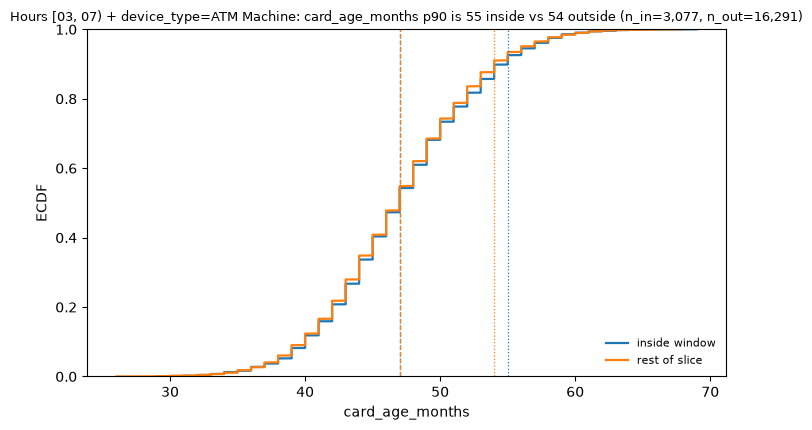

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_01_customer_age.png


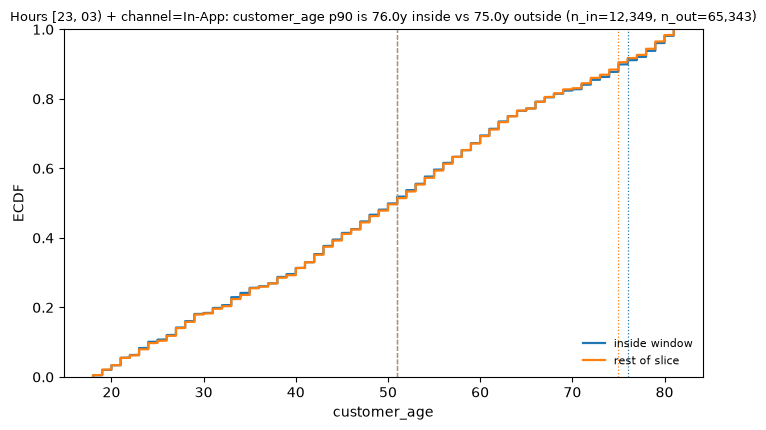

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_02_customer_age.png


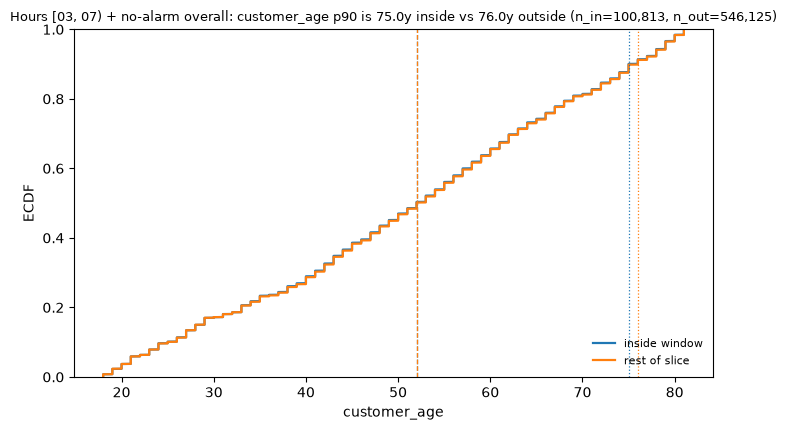

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_03_customer_age.png


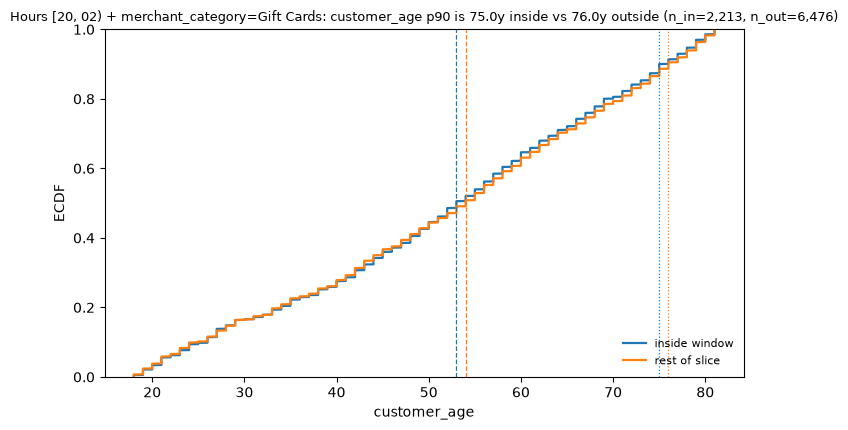

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_04_customer_age.png


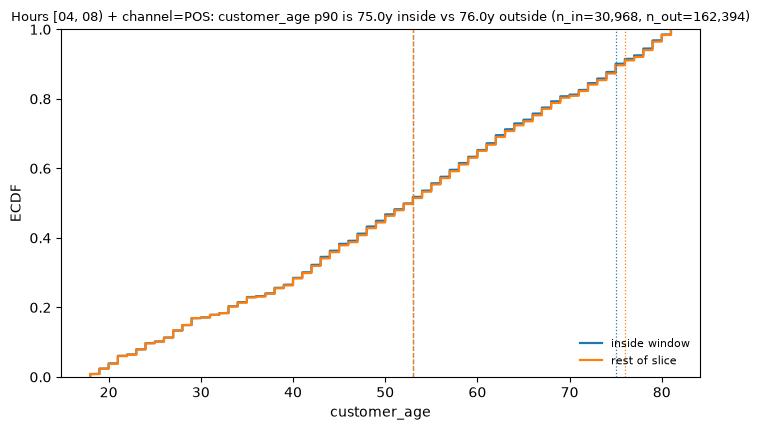

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_05_customer_age.png


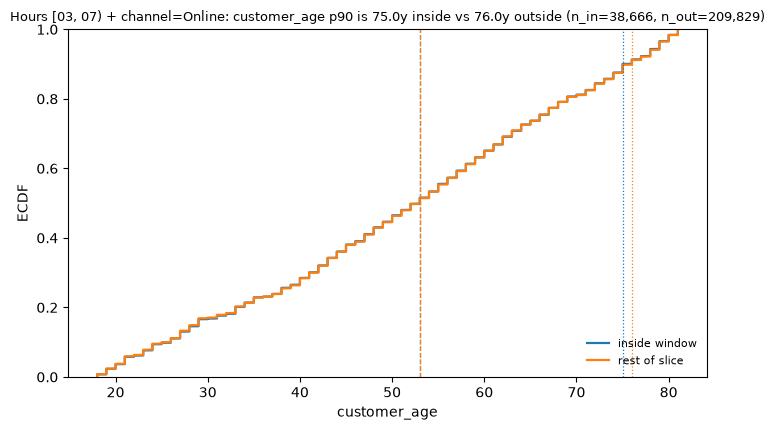

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_06_account_balance_usd.png


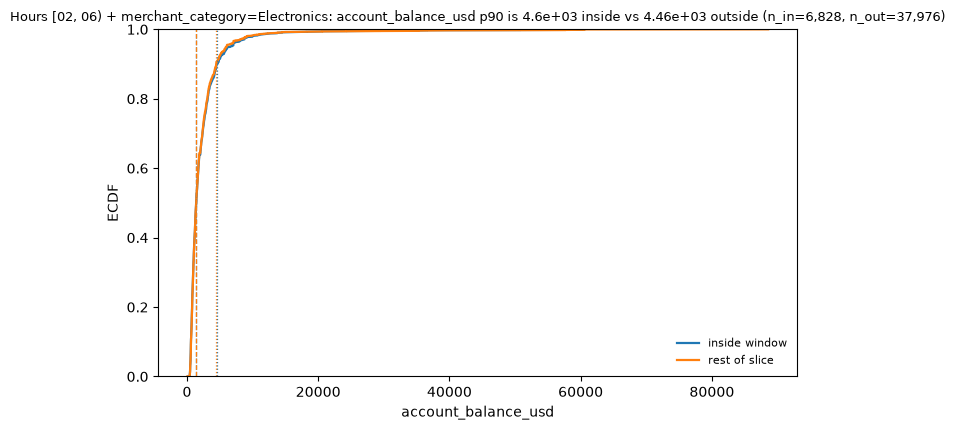

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_07_hours_since_last_txn.png


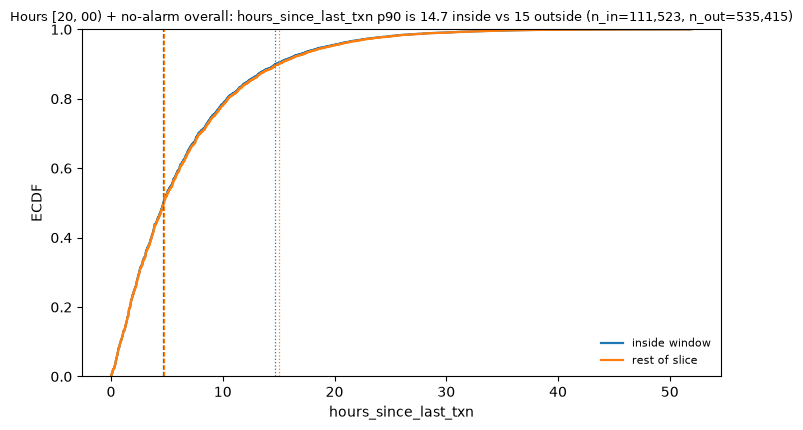

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_08_distance_from_home_km.png


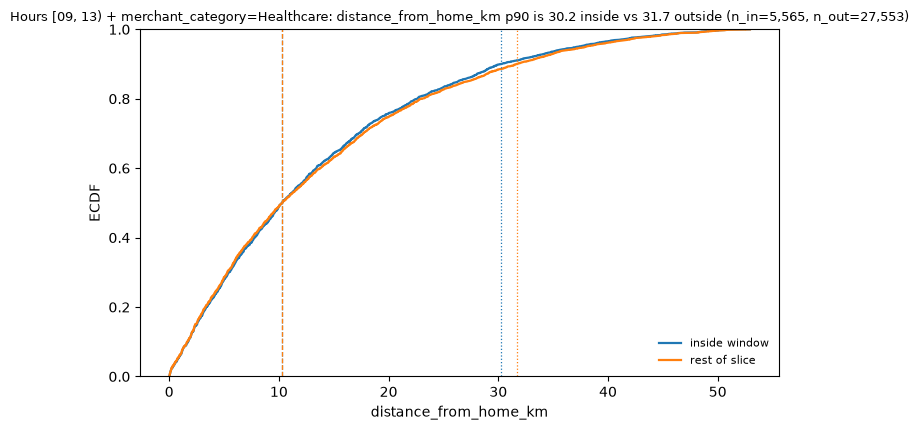

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_09_amount_usd.png


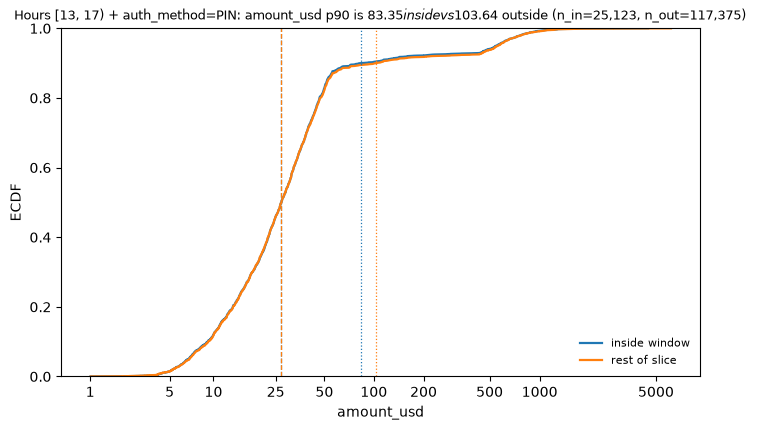

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_10_merchant_risk_score.png


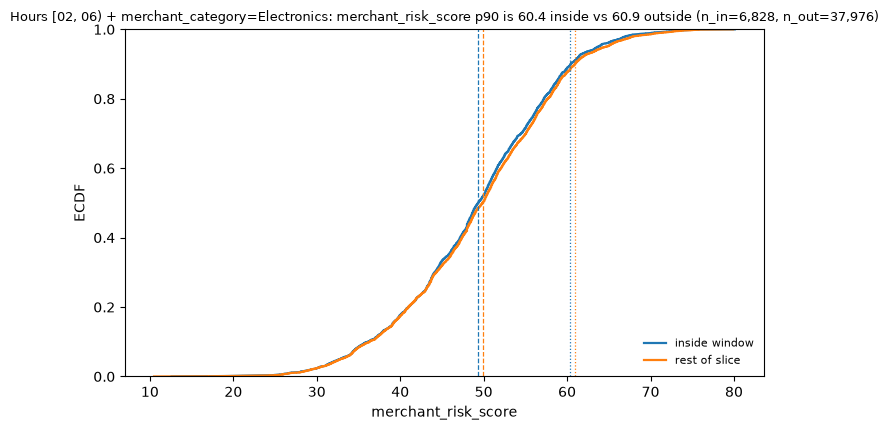

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_11_account_balance_usd.png


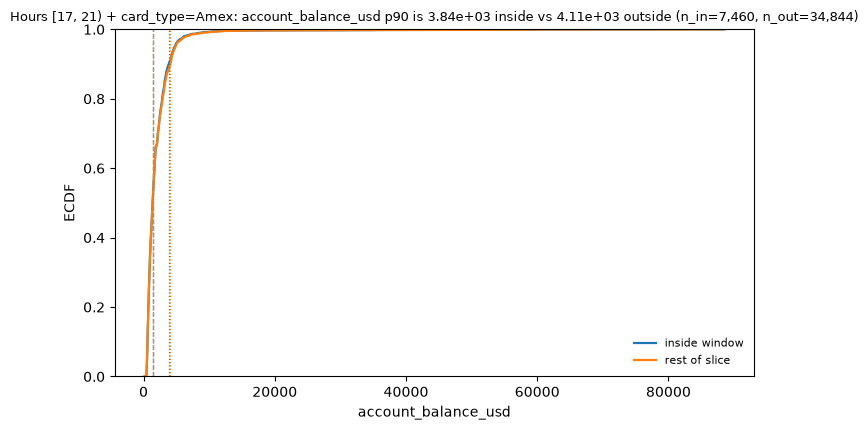

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_12_distance_from_home_km.png


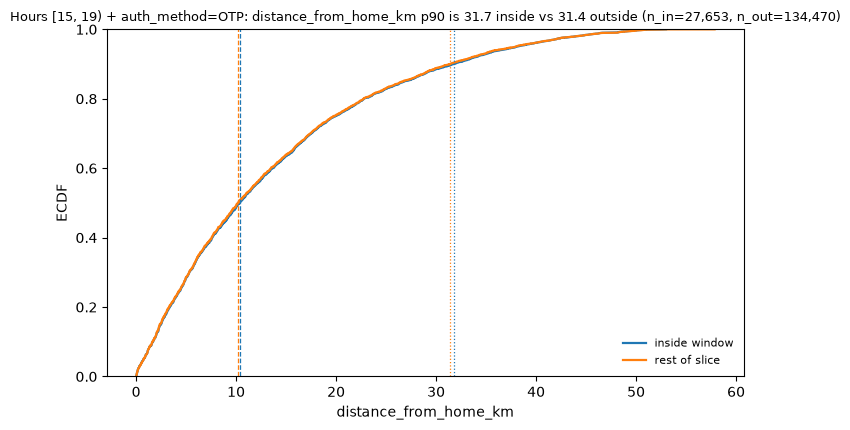

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_13_account_balance_usd.png


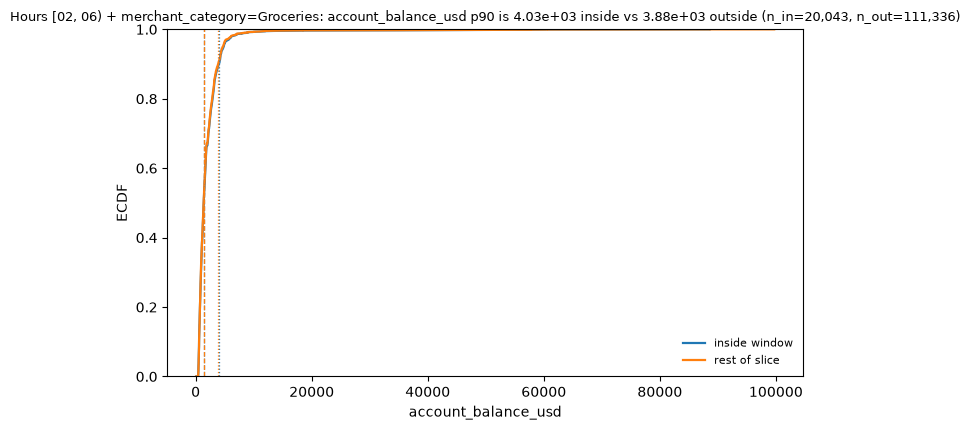

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_14_amount_usd.png


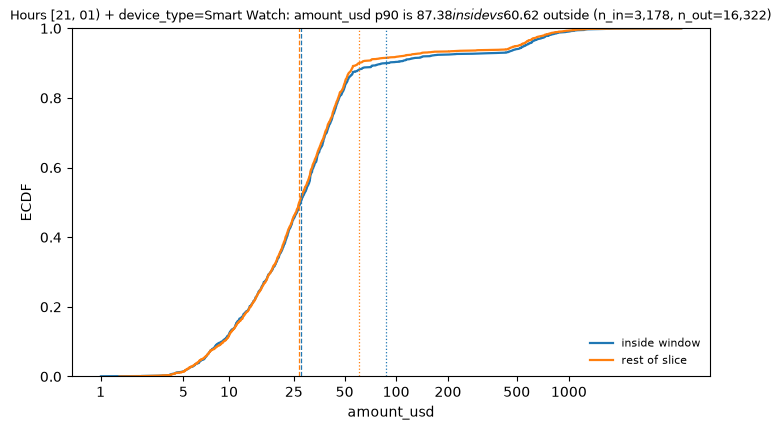

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_15_account_balance_usd.png


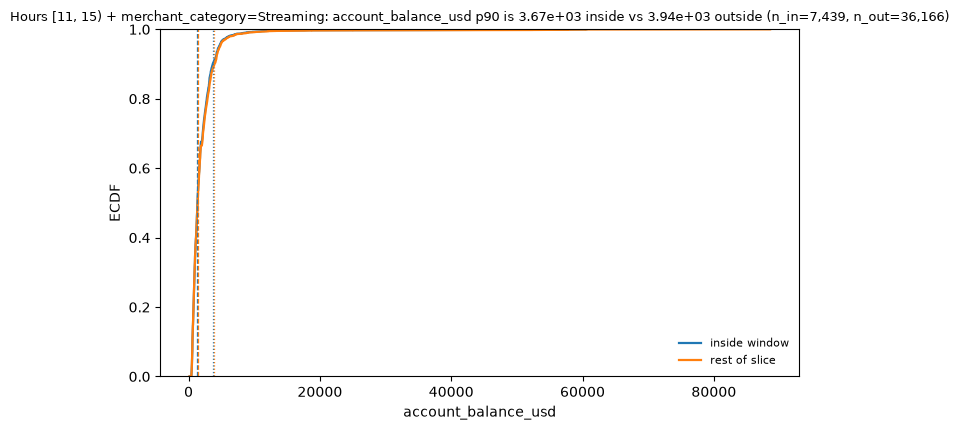

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_16_amount_usd.png


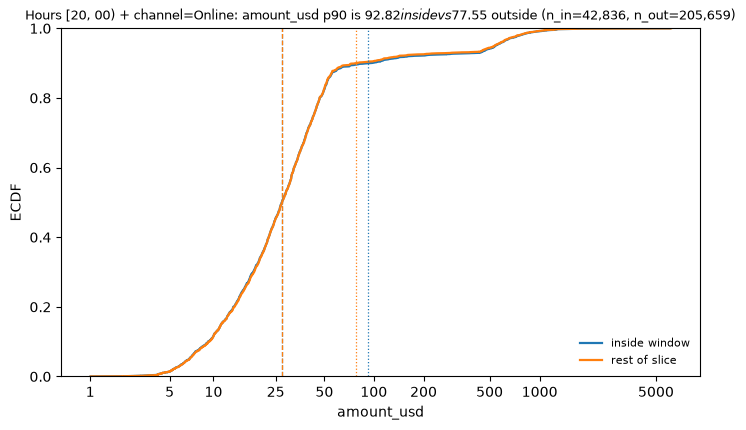

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_17_merchant_risk_score.png


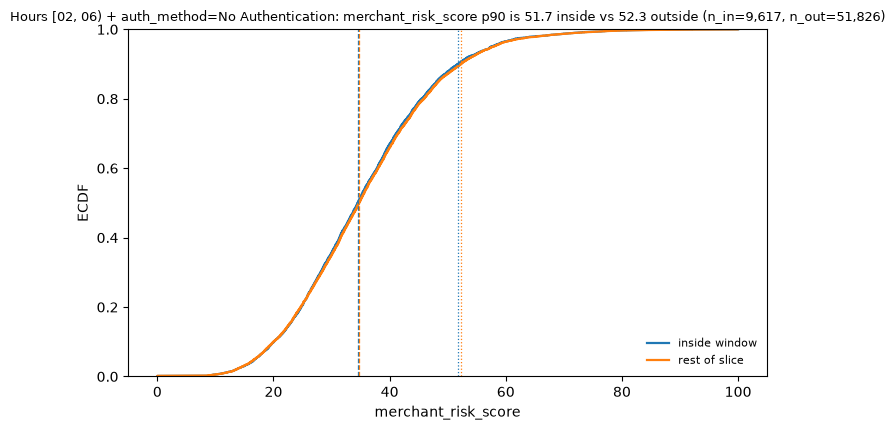

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_18_merchant_risk_score.png


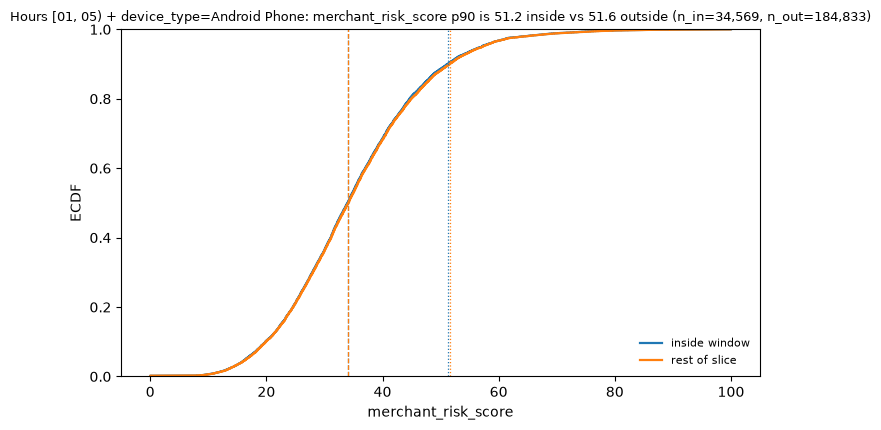

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\plots\p3_gallery\keeper_19_merchant_risk_score.png


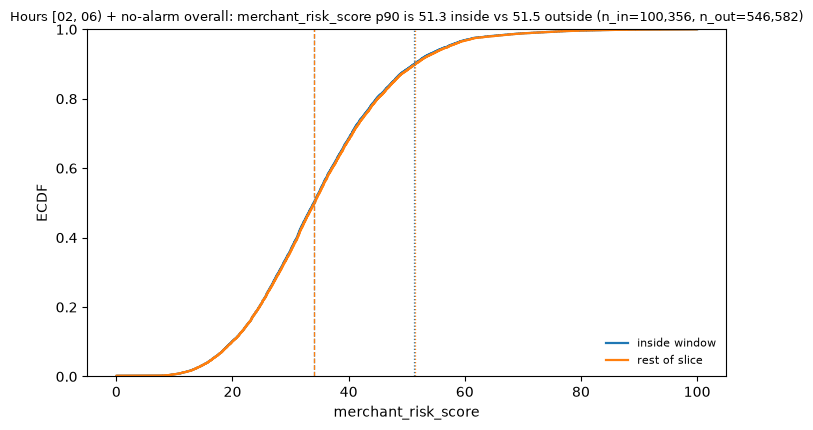

In [6]:
p3_dir = get_script_plot_dir(NOTEBOOK_STEM, section="p3_gallery")


def ecdf_xy(values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Sorted values and their empirical cumulative probabilities."""
    x = np.sort(values)
    n = x.size
    y = (np.arange(1, n + 1, dtype=np.float64)) / float(n)
    return x, y


def usd_log1p_ticks(ax, values_in: np.ndarray, values_out: np.ndarray) -> None:
    """Place USD tick labels on a log1p axis."""
    lo = float(min(values_in.min(), values_out.min()))
    hi = float(max(values_in.max(), values_out.max()))
    candidates = np.array(
        [1.0, 5.0, 10.0, 25.0, 50.0, 100.0, 200.0, 500.0, 1000.0, 5000.0, 20000.0]
    )
    ticks = candidates[(candidates >= max(lo, 1.0)) & (candidates <= hi)]
    if ticks.size == 0:
        ticks = np.array([max(lo, 1.0), hi], dtype=np.float64)
    ax.set_xticks(np.log1p(ticks))
    ax.set_xticklabels([f"{int(tick)}" for tick in ticks])
    ax.set_xlabel("amount_usd")


if keepers.empty:
    print("P3 skipped: no keepers")
else:
    gallery = keepers.head(N_GALLERY).copy()
    n_gallery = len(gallery)
    for i in range(n_gallery):
        row = gallery.iloc[i]
        mask = slice_mask_from_spec(
            row["slice_col"], row["slice_level"], slice_lookup=slice_lookup
        )
        start = int(row["window_start"])
        length = int(row["window_length"])
        hour_mask = np.zeros(N_HOURS, dtype=bool)
        for offset in range(length):
            hour_mask[(start + offset) % N_HOURS] = True
        in_mask = mask & hour_mask[hours]
        out_mask = mask & ~hour_mask[hours]
        numeric_name = str(row["numeric"])
        vals_in = numeric_values[numeric_name][in_mask]
        vals_out = numeric_values[numeric_name][out_mask]
        x_in, y_in = ecdf_xy(vals_in)
        x_out, y_out = ecdf_xy(vals_out)
        use_log = numeric_name == AMOUNT_COL
        fig, ax = plt.subplots(figsize=(7.2, 4.4))
        if use_log:
            ax.plot(np.log1p(x_in), y_in, lw=1.6, label="inside window")
            ax.plot(np.log1p(x_out), y_out, lw=1.6, label="rest of slice")
            ax.axvline(np.log1p(float(row["p50_in"])), color="C0", ls="--", lw=0.9)
            ax.axvline(np.log1p(float(row["p90_in"])), color="C0", ls=":", lw=0.9)
            ax.axvline(np.log1p(float(row["p50_out"])), color="C1", ls="--", lw=0.9)
            ax.axvline(np.log1p(float(row["p90_out"])), color="C1", ls=":", lw=0.9)
            usd_log1p_ticks(ax, vals_in, vals_out)
        else:
            ax.plot(x_in, y_in, lw=1.6, label="inside window")
            ax.plot(x_out, y_out, lw=1.6, label="rest of slice")
            ax.axvline(float(row["p50_in"]), color="C0", ls="--", lw=0.9)
            ax.axvline(float(row["p90_in"]), color="C0", ls=":", lw=0.9)
            ax.axvline(float(row["p50_out"]), color="C1", ls="--", lw=0.9)
            ax.axvline(float(row["p90_out"]), color="C1", ls=":", lw=0.9)
            ax.set_xlabel(numeric_name)
        ax.set_ylabel("ECDF")
        ax.set_ylim(0.0, 1.0)
        ax.legend(loc="lower right", fontsize=8, frameon=False)
        ax.set_title(row["sentence"], fontsize=9)
        fig.tight_layout()
        plot_path = p3_dir / f"keeper_{i:02d}_{numeric_name}.png"
        fig.savefig(plot_path, dpi=140)
        print("saved", plot_path)
        plt.show()
        plt.close(fig)


## P4: fraud overlay (keepers only)

Unusualness keepers: cut at the pocket p90. Compare the fraud rate above vs below that cut *inside* the window, and apply the same cut to the rest of the slice (so we know it is the pocket's scale, not "big values are always riskier"). Mix keepers: fraud rate of ages [18, 25] inside the pocket vs the rest of the pocket, with the same band's rate outside the window as a reading aid.

A row is `too_thin` if the unusual side has fewer than 10 frauds inside the pocket. It is a `distill_candidate` only if the unusual-side fraud rate is at least `1.1×` both the usual side of the pocket and the same cutoff/band outside the window. Otherwise `curiosity`.

Mann-Whitney (numeric in vs out) and a 2×2 chi-square on the overlay sit as footnotes; they are not the ranking.


saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\time_pocket_mining\tables\fraud_overlay.csv
        slice_col       slice_level               numeric     readout window_label                       unusual_name      cut  n_unusual_in  n_usual_in  n_unusual_out  fraud_unusual_in  fraud_usual_in  fraud_unusual_out  rate_unusual_in  rate_usual_in  rate_unusual_out  rate_usual_out  mannwhitney_p  chi2_unusual_in_vs_out_p           verdict
      device_type       ATM Machine       card_age_months   p90_ratio     [03, 07)       card_age_months > pocket_p90   55.000           229        2848           1067                 2              32                 13         0.008734       0.011236          0.012184        0.011889       0.138146                  0.918399          too_thin
          channel            In-App          customer_age   p90_ratio     [23, 03)          customer_age > pocket_p90   76.000          1097       11252          

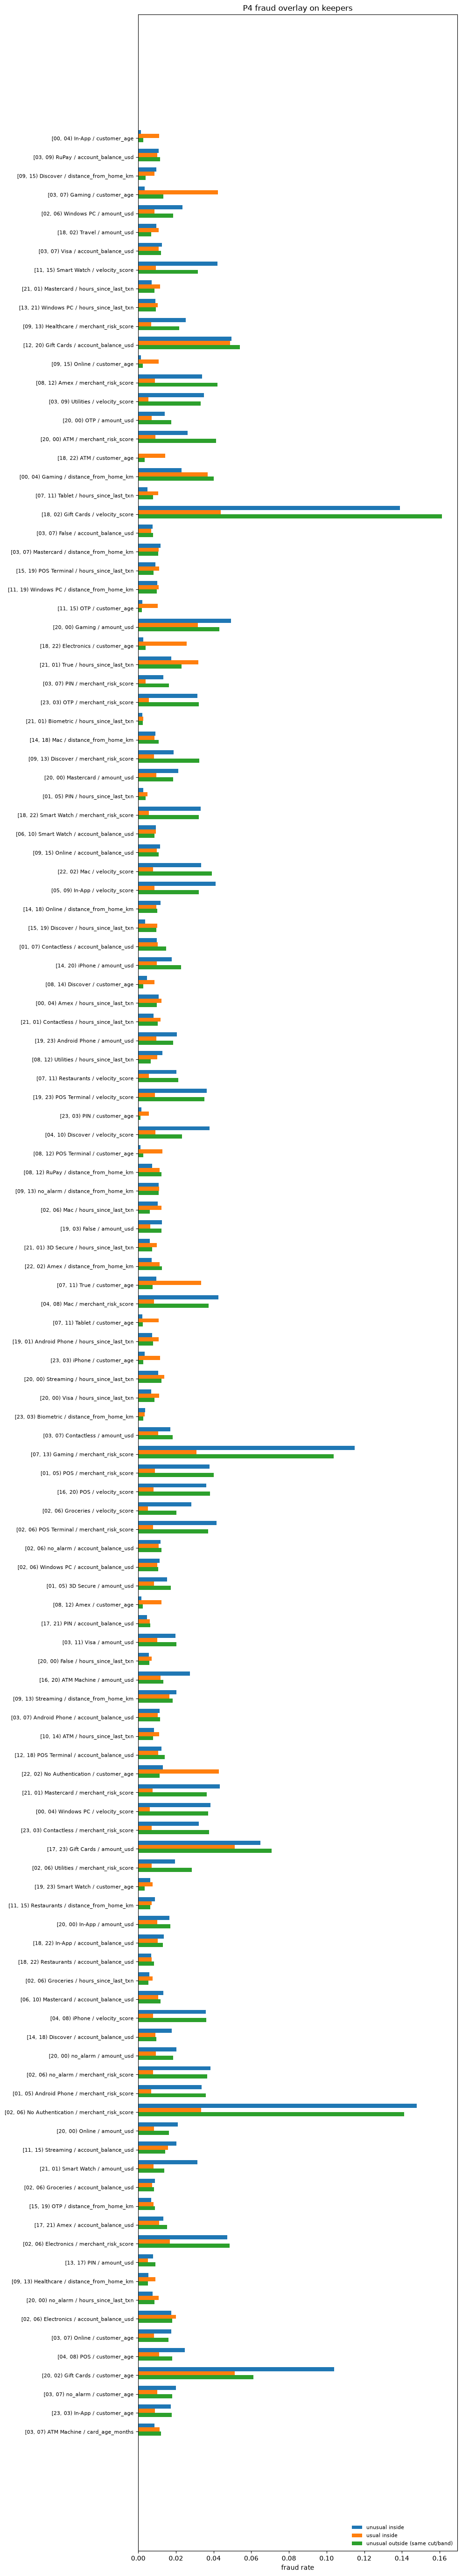

In [7]:
def rate_and_count(y_side: np.ndarray) -> tuple[float, int, int]:
    """Fraud rate, fraud count, n for a boolean-selected side."""
    n_side = int(y_side.size)
    n_fraud_side = int(y_side.sum()) if n_side else 0
    if n_side == 0:
        return float("nan"), 0, 0
    return float(n_fraud_side / n_side), n_fraud_side, n_side


def chi2_two_by_two(fraud_a, n_a, fraud_b, n_b):
    """Independence p-value for two groups x (fraud, not)."""
    table = np.array(
        [
            [int(fraud_a), int(n_a - fraud_a)],
            [int(fraud_b), int(n_b - fraud_b)],
        ],
        dtype=np.int64,
    )
    if (table < 0).any() or table.sum() == 0 or (table.sum(axis=1) == 0).any():
        return float("nan")
    if (table.sum(axis=0) == 0).any():
        return float("nan")
    _chi2, p_value, _dof, _expected = chi2_contingency(table)
    return float(p_value)


p4_dir = get_script_plot_dir(NOTEBOOK_STEM, section="p4_fraud")
if keepers.empty:
    overlay = pd.DataFrame()
    print("P4 skipped: no keepers")
else:
    n_keep_overlay = len(keepers)
    overlay_rows = [None] * n_keep_overlay
    for i in range(n_keep_overlay):
        row = keepers.iloc[i]
        mask = slice_mask_from_spec(
            row["slice_col"], row["slice_level"], slice_lookup=slice_lookup
        )
        start = int(row["window_start"])
        length = int(row["window_length"])
        hour_mask = np.zeros(N_HOURS, dtype=bool)
        for offset in range(length):
            hour_mask[(start + offset) % N_HOURS] = True
        in_mask = mask & hour_mask[hours]
        out_mask = mask & ~hour_mask[hours]
        numeric_name = str(row["numeric"])
        vals_in = numeric_values[numeric_name][in_mask]
        vals_out = numeric_values[numeric_name][out_mask]
        y_in = y[in_mask]
        y_out = y[out_mask]
        mw = mannwhitneyu(vals_in, vals_out, alternative="two-sided")
        readout = str(row["readout"])
        if readout == READOUT_YOUNG:
            unusual_in = (
                (vals_in >= YOUNG_AGE_LOW) & (vals_in <= YOUNG_AGE_HIGH)
            )
            unusual_out = (
                (vals_out >= YOUNG_AGE_LOW) & (vals_out <= YOUNG_AGE_HIGH)
            )
            unusual_name = "age_[18,25]"
            cut = float("nan")
        else:
            cut = float(row["p90_in"])
            unusual_in = vals_in > cut
            unusual_out = vals_out > cut
            unusual_name = f"{numeric_name} > pocket_p90"
        rate_u_in, fraud_u_in, n_u_in = rate_and_count(y_in[unusual_in])
        rate_n_in, fraud_n_in, n_n_in = rate_and_count(y_in[~unusual_in])
        rate_u_out, fraud_u_out, n_u_out = rate_and_count(y_out[unusual_out])
        rate_n_out, fraud_n_out, n_n_out = rate_and_count(y_out[~unusual_out])
        chi2_p = chi2_two_by_two(fraud_u_in, n_u_in, fraud_u_out, n_u_out)
        if fraud_u_in < MIN_FRAUD_ABOVE:
            verdict = "too_thin"
        else:
            beats_inside = (
                np.isfinite(rate_u_in)
                and np.isfinite(rate_n_in)
                and rate_u_in > RATE_MARGIN * rate_n_in
            )
            beats_outside = (
                np.isfinite(rate_u_in)
                and np.isfinite(rate_u_out)
                and rate_u_in > RATE_MARGIN * rate_u_out
            )
            if beats_inside and beats_outside:
                verdict = "distill_candidate"
            else:
                verdict = "curiosity"
        overlay_rows[i] = {
            "slice_col": row["slice_col"],
            "slice_level": row["slice_level"],
            "numeric": numeric_name,
            "readout": readout,
            "window_label": row["window_label"],
            "sentence": row["sentence"],
            "unusual_name": unusual_name,
            "cut": cut,
            "n_unusual_in": n_u_in,
            "n_usual_in": n_n_in,
            "n_unusual_out": n_u_out,
            "fraud_unusual_in": fraud_u_in,
            "fraud_usual_in": fraud_n_in,
            "fraud_unusual_out": fraud_u_out,
            "rate_unusual_in": rate_u_in,
            "rate_usual_in": rate_n_in,
            "rate_unusual_out": rate_u_out,
            "rate_usual_out": rate_n_out,
            "mannwhitney_p": float(mw.pvalue),
            "chi2_unusual_in_vs_out_p": chi2_p,
            "verdict": verdict,
        }
    overlay = pd.DataFrame(overlay_rows)
    overlay_path = tables_dir / "fraud_overlay.csv"
    overlay.to_csv(overlay_path, index=False)
    print("saved", overlay_path)
    print(overlay.drop(columns=["sentence"]).to_string(index=False))
    print(DELIMITER_VALUE)
    print(overlay[["verdict", "sentence"]].to_string(index=False))

    n_overlay = len(overlay)
    fig, ax = plt.subplots(figsize=(10.0, max(3.5, 0.45 * n_overlay)))
    y_pos = np.arange(n_overlay)
    height = 0.22
    ax.barh(
        y_pos + 1.5 * height,
        overlay["rate_unusual_in"].to_numpy(dtype=np.float64),
        height=height,
        label="unusual inside",
    )
    ax.barh(
        y_pos + 0.5 * height,
        overlay["rate_usual_in"].to_numpy(dtype=np.float64),
        height=height,
        label="usual inside",
    )
    ax.barh(
        y_pos - 0.5 * height,
        overlay["rate_unusual_out"].to_numpy(dtype=np.float64),
        height=height,
        label="unusual outside (same cut/band)",
    )
    labels = [
        f"{overlay.iloc[j]['window_label']} {overlay.iloc[j]['slice_level']} / {overlay.iloc[j]['numeric']}"
        for j in range(n_overlay)
    ]
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel("fraud rate")
    ax.legend(loc="lower right", fontsize=8, frameon=False)
    ax.set_title("P4 fraud overlay on keepers")
    fig.tight_layout()
    overlay_plot = p4_dir / "fraud_rates.png"
    fig.savefig(overlay_plot, dpi=140)
    print("saved", overlay_plot)
    plt.show()
    plt.close(fig)


## P5: English takeaway

- **Distill candidate:** a P2 keeper whose P4 tail (or band) is more fraudulent inside the window than the same cutoff outside it. Named follow-up (not this pass): percentile of that numeric within `(window × cat)`.
- **Generator curiosity, still drop raw time:** P2 keepers exist, P4 is flat or too thin.
- **Drop:** P0 looks flat and nothing survives P2.


In [8]:
n_keepers = 0 if keepers.empty else len(keepers)
if overlay.empty:
    n_distill = 0
    n_curiosity = 0
    n_thin = 0
    distill_rows = pd.DataFrame()
else:
    n_distill = int((overlay["verdict"] == "distill_candidate").sum())
    n_curiosity = int((overlay["verdict"] == "curiosity").sum())
    n_thin = int((overlay["verdict"] == "too_thin").sum())
    distill_rows = overlay.loc[overlay["verdict"] == "distill_candidate"]

if n_distill > 0:
    decision = "distill_candidate"
    lines = [
        "Decision: distill candidate (no OOF run in this pass).",
        (
            f"{n_distill} keeper(s) have an unusual side that is at least "
            f"{RATE_MARGIN}x more fraudulent inside the window than both the "
            "usual side of the pocket and the same cutoff/band outside it."
        ),
        "Named follow-up: percentile of that numeric within (window x cat).",
        "",
        "Distill keepers:",
    ]
    sentences = list(distill_rows["sentence"])
    n_s = len(sentences)
    for i in range(n_s):
        lines.append(f"- {sentences[i]}")
elif n_keepers > 0:
    decision = "curiosity_still_drop_raw_time"
    lines = [
        "Decision: generator curiosity, still drop raw time.",
        (
            f"{n_keepers} pocket(s) beat the shuffled clock "
            f"(P4: {n_curiosity} curiosity, {n_thin} too_thin, {n_distill} distill)."
        ),
        (
            "The clock changes mix or scale in those slices, but the unusual "
            "tail/band is not more fraudulent inside the window than the same "
            "cutoff outside it. That is a generator fact, not a ranking feature."
        ),
    ]
else:
    decision = "drop"
    lines = [
        "Decision: drop raw time in the no-alarm region.",
        (
            "No (slice, numeric, readout) window beat 1.1 x the most extreme "
            "window found after scrambling the hour labels."
        ),
        (
            "Consistent with M2/M5/M6 (fraud and age independent of hour; "
            "trees unused time) and with region ablations that already drop time."
        ),
    ]

takeaway = "\n".join(lines) + "\n"
takeaway_path = tables_dir / "takeaway.txt"
takeaway_path.write_text(takeaway, encoding="utf-8")
print(takeaway)
print("saved", takeaway_path)
print("decision", decision)


Decision: distill candidate (no OOF run in this pass).
24 keeper(s) have an unusual side that is at least 1.1x more fraudulent inside the window than both the usual side of the pocket and the same cutoff/band outside it.
Named follow-up: percentile of that numeric within (window x cat).

Distill keepers:
- Hours [03, 07) + no-alarm overall: customer_age p90 is 75.0y inside vs 76.0y outside (n_in=100,813, n_out=546,125)
- Hours [20, 02) + merchant_category=Gift Cards: customer_age p90 is 75.0y inside vs 76.0y outside (n_in=2,213, n_out=6,476)
- Hours [04, 08) + channel=POS: customer_age p90 is 75.0y inside vs 76.0y outside (n_in=30,968, n_out=162,394)
- Hours [21, 01) + device_type=Smart Watch: amount_usd p90 is $87.38 inside vs $60.62 outside (n_in=3,178, n_out=16,322)
- Hours [11, 15) + merchant_category=Streaming: account_balance_usd p90 is 3.67e+03 inside vs 3.94e+03 outside (n_in=7,439, n_out=36,166)
- Hours [20, 00) + channel=Online: amount_usd p90 is $92.82 inside vs $77.55 outsi